<a href="https://colab.research.google.com/github/devakipk/Uber-Data-Analysis/blob/main/uber_data_analysis_001.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Project Name :- EDA On Uber Data

Project Objective :-
The main objective of this project is to analyze Uber trip data using Python libraries to identify travel patterns, understand customer booking behaviour, and discover useful insights from trip records.

Importing Libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

print("Imported all libraries..")

Imported all libraries..


Step 1 :- Data Loading

In [ ]:
data = pd.read_csv('/content/UberDrives2016.csv.crdownload')

Step 2:- Data Exploration

In [ ]:
# Fetching all column details
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1156 entries, 0 to 1155
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   START_DATE*  1156 non-null   object 
 1   END_DATE*    1155 non-null   object 
 2   CATEGORY*    1155 non-null   object 
 3   START*       1155 non-null   object 
 4   STOP*        1155 non-null   object 
 5   MILES*       1156 non-null   float64
 6   PURPOSE*     653 non-null    object 
dtypes: float64(1), object(6)
memory usage: 63.3+ KB


In [ ]:
# showing basic details about data
print("Showing shape of data :\n",data.shape)

print("\nShowing all column names :\n",data.columns.tolist())

print("\nDescribing numerical columns :\n",data.describe())

Showing shape of data :
 (1156, 7)

Showing all column names :
 ['START_DATE*', 'END_DATE*', 'CATEGORY*', 'START*', 'STOP*', 'MILES*', 'PURPOSE*']

Describing numerical columns :
              MILES*
count   1156.000000
mean      21.115398
std      359.299007
min        0.500000
25%        2.900000
50%        6.000000
75%       10.400000
max    12204.700000


In [ ]:
# Displaying first 10 records
data.head(10)

,START_DATE*,END_DATE*,CATEGORY*,START*,STOP*,MILES*,PURPOSE*
0,1/1/2016 21:11,1/1/2016 21:17,Business,Fort Pierce,Fort Pierce,5.1,Meal/Entertain
1,1/2/2016 1:25,1/2/2016 1:37,Business,Fort Pierce,Fort Pierce,5.0,NaN
2,1/2/2016 20:25,1/2/2016 20:38,Business,Fort Pierce,Fort Pierce,4.8,Errand/Supplies
3,1/5/2016 17:31,1/5/2016 17:45,Business,Fort Pierce,Fort Pierce,4.7,Meeting
4,1/6/2016 14:42,1/6/2016 15:49,Business,Fort Pierce,West Palm Beach,63.7,Customer Visit
5,1/6/2016 17:15,1/6/2016 17:19,Business,West Palm Beach,West Palm Beach,4.3,Meal/Entertain
6,1/6/2016 17:30,1/6/2016 17:35,Business,West Palm Beach,Palm Beach,7.1,Meeting
7,1/7/2016 13:27,1/7/2016 13:33,Business,Cary,Cary,0.8,Meeting
8,1/10/2016 8:05,1/10/2016 8:25,Business,Cary,Morrisville,8.3,Meeting
9,1/10/2016 12:17,1/10/2016 12:44,Business,Jamaica,New York,16.5,Customer Visit


Step 3 :- Data Cleaning

In [ ]:
# checking is any null value present or not - counting nulls
data.isnull().sum()

,0
START_DATE*,0
END_DATE*,1
CATEGORY*,1
START*,1
STOP*,1
MILES*,0
PURPOSE*,503


Step 4 :- Handling missing values

In [ ]:
# filling all null values in purpose column - with frequently occured values(mode).
data['PURPOSE*'].fillna(data['PURPOSE*'].mode()[0], inplace=True)

In [ ]:
# checking data after updation of null values
data

,START_DATE*,END_DATE*,CATEGORY*,START*,STOP*,MILES*,PURPOSE*
0,1/1/2016 21:11,1/1/2016 21:17,Business,Fort Pierce,Fort Pierce,5.1,Meal/Entertain
1,1/2/2016 1:25,1/2/2016 1:37,Business,Fort Pierce,Fort Pierce,5.0,Meeting
2,1/2/2016 20:25,1/2/2016 20:38,Business,Fort Pierce,Fort Pierce,4.8,Errand/Supplies
3,1/5/2016 17:31,1/5/2016 17:45,Business,Fort Pierce,Fort Pierce,4.7,Meeting
4,1/6/2016 14:42,1/6/2016 15:49,Business,Fort Pierce,West Palm Beach,63.7,Customer Visit
...,...,...,...,...,...,...,...
1151,12/31/2016 13:24,12/31/2016 13:42,Business,Kar?chi,Unknown Location,3.9,Temporary Site
1152,12/31/2016 15:03,12/31/2016 15:38,Business,Unknown Location,Unknown Location,16.2,Meeting
1153,12/31/2016 21:32,12/31/2016 21:50,Business,Katunayake,Gampaha,6.4,Temporary Site
1154,12/31/2016 22:08,12/31/2016 23:51,Business,Gampaha,Ilukwatta,48.2,Temporary Site


In [ ]:
# now check with null values - count them also
data.isnull().sum()

,0
START_DATE*,0
END_DATE*,1
CATEGORY*,1
START*,1
STOP*,1
MILES*,0
PURPOSE*,0


In [ ]:
# droping that some null values
data.dropna(inplace=True)

Step 5 :- checking duplicate

In [ ]:
duplicate = data[data.duplicated() ]

In [ ]:
print("Showing Duplicate Records Count:\n")
print(data.duplicated().sum())

Showing Duplicate Records Count:

1


In [ ]:
# Removing that 1 duplicated record
data.drop_duplicates(inplace=True)

In [ ]:
# counting again to check for confirmation
print(data.duplicated().sum())

0


Step 6 :- Data Analysis

In [ ]:
# fetching records that having category as business only.
data.loc[data['CATEGORY*']=='Business']

,START_DATE*,END_DATE*,CATEGORY*,START*,STOP*,MILES*,PURPOSE*
0,1/1/2016 21:11,1/1/2016 21:17,Business,Fort Pierce,Fort Pierce,5.1,Meal/Entertain
1,1/2/2016 1:25,1/2/2016 1:37,Business,Fort Pierce,Fort Pierce,5.0,Meeting
2,1/2/2016 20:25,1/2/2016 20:38,Business,Fort Pierce,Fort Pierce,4.8,Errand/Supplies
3,1/5/2016 17:31,1/5/2016 17:45,Business,Fort Pierce,Fort Pierce,4.7,Meeting
4,1/6/2016 14:42,1/6/2016 15:49,Business,Fort Pierce,West Palm Beach,63.7,Customer Visit
...,...,...,...,...,...,...,...
1150,12/31/2016 1:07,12/31/2016 1:14,Business,Kar?chi,Kar?chi,0.7,Meeting
1151,12/31/2016 13:24,12/31/2016 13:42,Business,Kar?chi,Unknown Location,3.9,Temporary Site
1152,12/31/2016 15:03,12/31/2016 15:38,Business,Unknown Location,Unknown Location,16.2,Meeting
1153,12/31/2016 21:32,12/31/2016 21:50,Business,Katunayake,Gampaha,6.4,Temporary Site


In [ ]:
# fetching personal category with having only 'Meeting' as a purpose
data[(data['CATEGORY*']=='Personal') & (data['PURPOSE*']=='Meeting')]

,START_DATE*,END_DATE*,CATEGORY*,START*,STOP*,MILES*,PURPOSE*
85,2/9/2016 10:54,2/9/2016 11:07,Personal,Whitebridge,Northwoods,5.3,Meeting
86,2/9/2016 11:43,2/9/2016 11:50,Personal,Northwoods,Tanglewood,3.0,Meeting
87,2/9/2016 13:36,2/9/2016 13:52,Personal,Tanglewood,Preston,5.1,Meeting
88,2/9/2016 13:58,2/9/2016 14:02,Personal,Preston,Whitebridge,1.5,Meeting
102,2/13/2016 23:45,2/14/2016 0:01,Personal,East Elmhurst,Jackson Heights,2.7,Meeting
...,...,...,...,...,...,...,...
556,7/16/2016 21:45,7/16/2016 22:18,Personal,Banner Elk,Banner Elk,13.0,Meeting
573,7/19/2016 17:50,7/19/2016 18:08,Personal,Chessington,Whitebridge,4.8,Meeting
574,7/20/2016 17:12,7/20/2016 17:24,Personal,Whitebridge,Edgehill Farms,2.8,Meeting
575,7/20/2016 17:50,7/20/2016 17:57,Personal,Edgehill Farms,Preston,1.4,Meeting


In [ ]:
# calculate the average miles driven for Business trips
data.loc[data['CATEGORY*']=='Business', 'MILES*'].mean()

np.float64(10.656545961002786)

In [ ]:
# Count the number of trips per purpose category
purpose_counts = data['PURPOSE*'].value_counts()
display(purpose_counts)

,count
PURPOSE*,
Meeting,688
Meal/Entertain,160
Errand/Supplies,128
Customer Visit,101
Temporary Site,50
Between Offices,18
Moving,4
Airport/Travel,3
Commute,1


In [ ]:
# calculate the average miles driven for each purpose category
avg_miles_purpose = data.groupby('PURPOSE*')['MILES*'].mean()
display(avg_miles_purpose)

,MILES*
PURPOSE*,
Airport/Travel,5.500000
Between Offices,10.944444
Charity ($),15.100000
Commute,180.200000
Customer Visit,20.688119
Errand/Supplies,3.968750
Meal/Entertain,5.698125
Meeting,11.242587
Moving,4.550000


In [ ]:
# identify the top 10 most frequent start location in the dataset
top_3_start_locations = data['START*'].value_counts().head(10)
display(top_3_start_locations)

,count
START*,
Cary,201
Unknown Location,148
Morrisville,85
Whitebridge,68
Islamabad,57
Durham,36
Lahore,36
Raleigh,28
Kar?chi,27


Step 7 :- Feature Creation

In [ ]:
# Remove the summary 'Totals' row before converting datetimes
data = data[data['START_DATE*'] != 'Totals']

# calculate the duration of each trip from start_date and end_date
data['START_DATE*'] = pd.to_datetime(data['START_DATE*'])
data['END_DATE*'] = pd.to_datetime(data['END_DATE*'])

trip_duration = data['END_DATE*'] - data['START_DATE*']
data['TRIP_DURATION_TIME']=((trip_duration).dt.total_seconds()/60)
data

,START_DATE*,END_DATE*,CATEGORY*,START*,STOP*,MILES*,PURPOSE*,TRIP_DURATION_TIME
0,2016-01-01 21:11:00,2016-01-01 21:17:00,Business,Fort Pierce,Fort Pierce,5.1,Meal/Entertain,6.0
1,2016-01-02 01:25:00,2016-01-02 01:37:00,Business,Fort Pierce,Fort Pierce,5.0,Meeting,12.0
2,2016-01-02 20:25:00,2016-01-02 20:38:00,Business,Fort Pierce,Fort Pierce,4.8,Errand/Supplies,13.0
3,2016-01-05 17:31:00,2016-01-05 17:45:00,Business,Fort Pierce,Fort Pierce,4.7,Meeting,14.0
4,2016-01-06 14:42:00,2016-01-06 15:49:00,Business,Fort Pierce,West Palm Beach,63.7,Customer Visit,67.0
...,...,...,...,...,...,...,...,...
1150,2016-12-31 01:07:00,2016-12-31 01:14:00,Business,Kar?chi,Kar?chi,0.7,Meeting,7.0
1151,2016-12-31 13:24:00,2016-12-31 13:42:00,Business,Kar?chi,Unknown Location,3.9,Temporary Site,18.0
1152,2016-12-31 15:03:00,2016-12-31 15:38:00,Business,Unknown Location,Unknown Location,16.2,Meeting,35.0
1153,2016-12-31 21:32:00,2016-12-31 21:50:00,Business,Katunayake,Gampaha,6.4,Temporary Site,18.0


In [ ]:
# calculate avg speed of each trip (duration) to identify potential traffic.
data['AVG_SPEED'] = data['MILES*'] / (data['TRIP_DURATION_TIME'] / 60)
data

,START_DATE*,END_DATE*,CATEGORY*,START*,STOP*,MILES*,PURPOSE*,TRIP_DURATION_TIME,AVG_SPEED
0,2016-01-01 21:11:00,2016-01-01 21:17:00,Business,Fort Pierce,Fort Pierce,5.1,Meal/Entertain,6.0,51.000000
1,2016-01-02 01:25:00,2016-01-02 01:37:00,Business,Fort Pierce,Fort Pierce,5.0,Meeting,12.0,25.000000
2,2016-01-02 20:25:00,2016-01-02 20:38:00,Business,Fort Pierce,Fort Pierce,4.8,Errand/Supplies,13.0,22.153846
3,2016-01-05 17:31:00,2016-01-05 17:45:00,Business,Fort Pierce,Fort Pierce,4.7,Meeting,14.0,20.142857
4,2016-01-06 14:42:00,2016-01-06 15:49:00,Business,Fort Pierce,West Palm Beach,63.7,Customer Visit,67.0,57.044776
...,...,...,...,...,...,...,...,...,...
1150,2016-12-31 01:07:00,2016-12-31 01:14:00,Business,Kar?chi,Kar?chi,0.7,Meeting,7.0,6.000000
1151,2016-12-31 13:24:00,2016-12-31 13:42:00,Business,Kar?chi,Unknown Location,3.9,Temporary Site,18.0,13.000000
1152,2016-12-31 15:03:00,2016-12-31 15:38:00,Business,Unknown Location,Unknown Location,16.2,Meeting,35.0,27.771429
1153,2016-12-31 21:32:00,2016-12-31 21:50:00,Business,Katunayake,Gampaha,6.4,Temporary Site,18.0,21.333333


In [ ]:
# Can we create categorical features for MILES*
conditions = [
    (data['MILES*'] <= 10),
    (data['MILES*'] > 10) & (data['MILES*'] <= 30),
    (data['MILES*'] > 30)
]
choices = ['Short Trip', 'Medium Trip', 'Long Trip']
data['MILES_CATEGORY'] = np.select(conditions, choices, default='Unknown')
data

,START_DATE*,END_DATE*,CATEGORY*,START*,STOP*,MILES*,PURPOSE*,TRIP_DURATION_TIME,AVG_SPEED,MILES_CATEGORY
0,2016-01-01 21:11:00,2016-01-01 21:17:00,Business,Fort Pierce,Fort Pierce,5.1,Meal/Entertain,6.0,51.000000,Short Trip
1,2016-01-02 01:25:00,2016-01-02 01:37:00,Business,Fort Pierce,Fort Pierce,5.0,Meeting,12.0,25.000000,Short Trip
2,2016-01-02 20:25:00,2016-01-02 20:38:00,Business,Fort Pierce,Fort Pierce,4.8,Errand/Supplies,13.0,22.153846,Short Trip
3,2016-01-05 17:31:00,2016-01-05 17:45:00,Business,Fort Pierce,Fort Pierce,4.7,Meeting,14.0,20.142857,Short Trip
4,2016-01-06 14:42:00,2016-01-06 15:49:00,Business,Fort Pierce,West Palm Beach,63.7,Customer Visit,67.0,57.044776,Long Trip
...,...,...,...,...,...,...,...,...,...,...
1150,2016-12-31 01:07:00,2016-12-31 01:14:00,Business,Kar?chi,Kar?chi,0.7,Meeting,7.0,6.000000,Short Trip
1151,2016-12-31 13:24:00,2016-12-31 13:42:00,Business,Kar?chi,Unknown Location,3.9,Temporary Site,18.0,13.000000,Short Trip
1152,2016-12-31 15:03:00,2016-12-31 15:38:00,Business,Unknown Location,Unknown Location,16.2,Meeting,35.0,27.771429,Medium Trip
1153,2016-12-31 21:32:00,2016-12-31 21:50:00,Business,Katunayake,Gampaha,6.4,Temporary Site,18.0,21.333333,Short Trip


In [ ]:
# create a feature to indicate if a trip occurred on a 'weekday' or 'weekend'?
data['START_DATE*'] = pd.to_datetime(data['START_DATE*'])
day_of_week = data['START_DATE*'].dt.dayofweek
data['DAY_TYPE'] = day_of_week.apply(lambda x:'Weekday'  if x <= 4 else 'Weekend')
data

,START_DATE*,END_DATE*,CATEGORY*,START*,STOP*,MILES*,PURPOSE*,TRIP_DURATION_TIME,AVG_SPEED,MILES_CATEGORY,DAY_TYPE
0,2016-01-01 21:11:00,2016-01-01 21:17:00,Business,Fort Pierce,Fort Pierce,5.1,Meal/Entertain,6.0,51.000000,Short Trip,Weekday
1,2016-01-02 01:25:00,2016-01-02 01:37:00,Business,Fort Pierce,Fort Pierce,5.0,Meeting,12.0,25.000000,Short Trip,Weekend
2,2016-01-02 20:25:00,2016-01-02 20:38:00,Business,Fort Pierce,Fort Pierce,4.8,Errand/Supplies,13.0,22.153846,Short Trip,Weekend
3,2016-01-05 17:31:00,2016-01-05 17:45:00,Business,Fort Pierce,Fort Pierce,4.7,Meeting,14.0,20.142857,Short Trip,Weekday
4,2016-01-06 14:42:00,2016-01-06 15:49:00,Business,Fort Pierce,West Palm Beach,63.7,Customer Visit,67.0,57.044776,Long Trip,Weekday
...,...,...,...,...,...,...,...,...,...,...,...
1150,2016-12-31 01:07:00,2016-12-31 01:14:00,Business,Kar?chi,Kar?chi,0.7,Meeting,7.0,6.000000,Short Trip,Weekend
1151,2016-12-31 13:24:00,2016-12-31 13:42:00,Business,Kar?chi,Unknown Location,3.9,Temporary Site,18.0,13.000000,Short Trip,Weekend
1152,2016-12-31 15:03:00,2016-12-31 15:38:00,Business,Unknown Location,Unknown Location,16.2,Meeting,35.0,27.771429,Medium Trip,Weekend
1153,2016-12-31 21:32:00,2016-12-31 21:50:00,Business,Katunayake,Gampaha,6.4,Temporary Site,18.0,21.333333,Short Trip,Weekend


In [ ]:
# identify if a trip is a round trip (where START* and STOP* are the same location)?
conditions=[
    (data['START*'] == data['STOP*'])
]
choices = ['Round Trip']
data['TRIP_TYPE'] = np.select(conditions, choices, default='One Way')
data

,START_DATE*,END_DATE*,CATEGORY*,START*,STOP*,MILES*,PURPOSE*,TRIP_DURATION_TIME,AVG_SPEED,MILES_CATEGORY,DAY_TYPE,TRIP_TYPE
0,2016-01-01 21:11:00,2016-01-01 21:17:00,Business,Fort Pierce,Fort Pierce,5.1,Meal/Entertain,6.0,51.000000,Short Trip,Weekday,Round Trip
1,2016-01-02 01:25:00,2016-01-02 01:37:00,Business,Fort Pierce,Fort Pierce,5.0,Meeting,12.0,25.000000,Short Trip,Weekend,Round Trip
2,2016-01-02 20:25:00,2016-01-02 20:38:00,Business,Fort Pierce,Fort Pierce,4.8,Errand/Supplies,13.0,22.153846,Short Trip,Weekend,Round Trip
3,2016-01-05 17:31:00,2016-01-05 17:45:00,Business,Fort Pierce,Fort Pierce,4.7,Meeting,14.0,20.142857,Short Trip,Weekday,Round Trip
4,2016-01-06 14:42:00,2016-01-06 15:49:00,Business,Fort Pierce,West Palm Beach,63.7,Customer Visit,67.0,57.044776,Long Trip,Weekday,One Way
...,...,...,...,...,...,...,...,...,...,...,...,...
1150,2016-12-31 01:07:00,2016-12-31 01:14:00,Business,Kar?chi,Kar?chi,0.7,Meeting,7.0,6.000000,Short Trip,Weekend,Round Trip
1151,2016-12-31 13:24:00,2016-12-31 13:42:00,Business,Kar?chi,Unknown Location,3.9,Temporary Site,18.0,13.000000,Short Trip,Weekend,One Way
1152,2016-12-31 15:03:00,2016-12-31 15:38:00,Business,Unknown Location,Unknown Location,16.2,Meeting,35.0,27.771429,Medium Trip,Weekend,Round Trip
1153,2016-12-31 21:32:00,2016-12-31 21:50:00,Business,Katunayake,Gampaha,6.4,Temporary Site,18.0,21.333333,Short Trip,Weekend,One Way


Step 8 :- Data Visualization

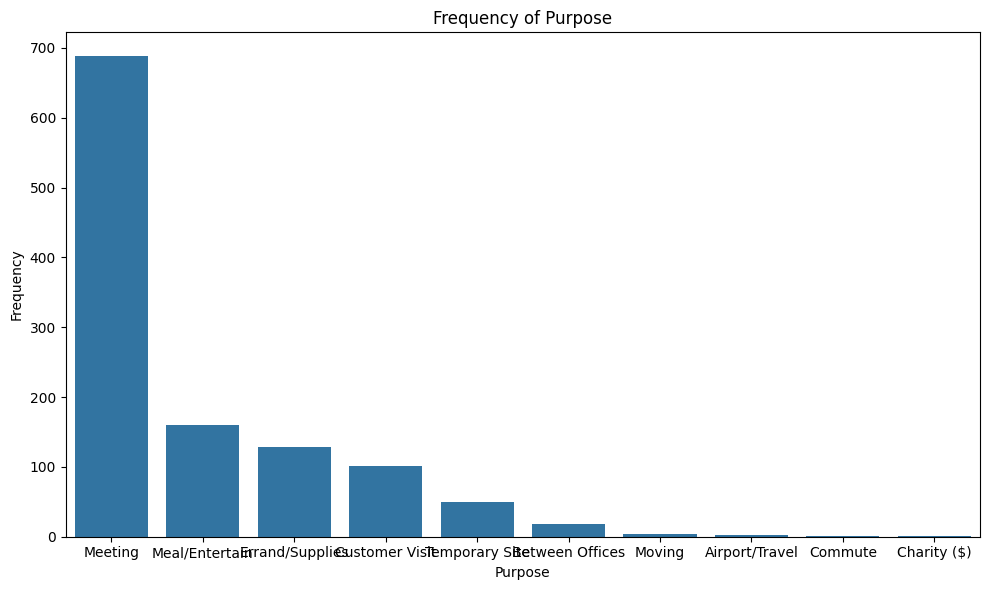

In [ ]:
# plotting graph to show frequency of purpose
plt.figure(figsize=(10, 6))
sns.countplot(data=data, x='PURPOSE*', order=data['PURPOSE*'].value_counts().index)
plt.xlabel('Purpose')
plt.ylabel('Frequency')
plt.title('Frequency of Purpose')
plt.tight_layout()
plt.show()

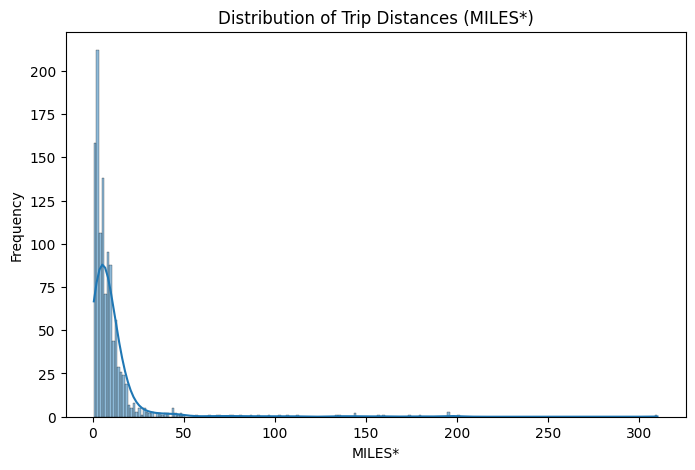

In [ ]:
# plotting graph to show distribution of trip distance in miles
plt.figure(figsize=(8,5))
sns.histplot(data['MILES*'], kde=True)
plt.xlabel('MILES*')
plt.ylabel('Frequency')
plt.title('Distribution of Trip Distances (MILES*)')
plt.show()

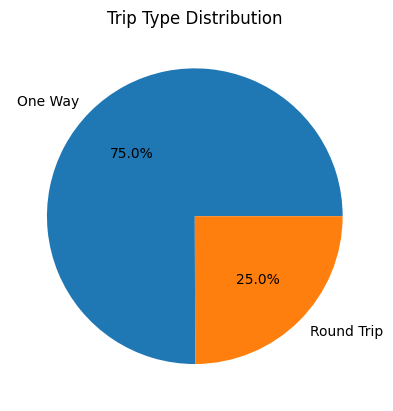

In [ ]:
# plotting pie chart to show trip type distribution
trip_type_counts = data['TRIP_TYPE'].value_counts()
plt.pie(trip_type_counts, labels=trip_type_counts.index,autopct='%1.1f%%')
plt.title('Trip Type Distribution')
plt.show()

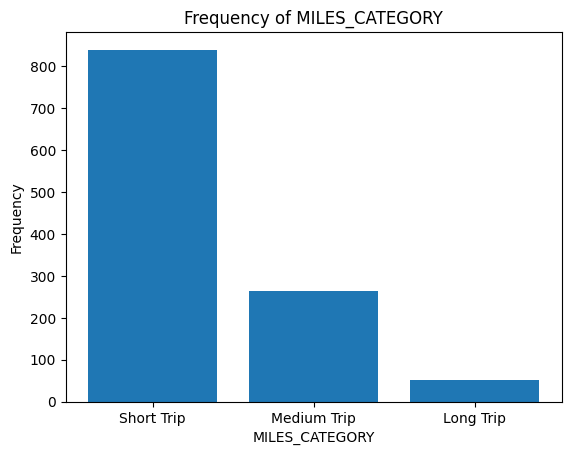

In [ ]:
# plotting graph to show frequency of miles category
plt.bar(data['MILES_CATEGORY'].value_counts().index, data['MILES_CATEGORY'].value_counts())
plt.xlabel('MILES_CATEGORY')
plt.ylabel('Frequency')
plt.title('Frequency of MILES_CATEGORY')
plt.show()

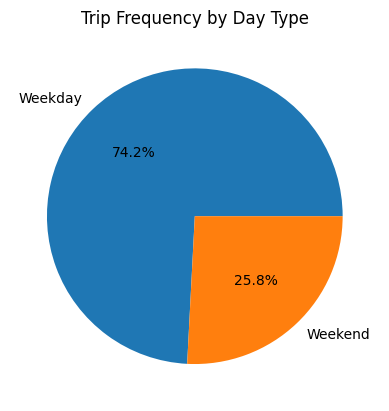

In [ ]:
plt.pie(data['DAY_TYPE'].value_counts(), labels=data['DAY_TYPE'].unique(), autopct='%1.1f%%')
plt.title('Trip Frequency by Day Type')
plt.show()

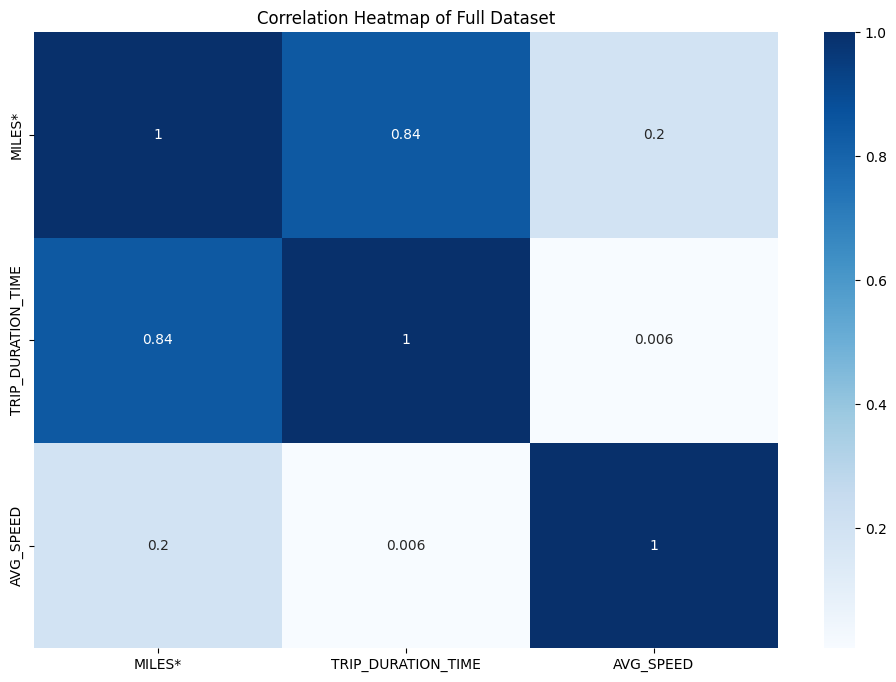

In [ ]:
# plotting heatmap to show correlation between numerical columns
plt.figure(figsize=(12, 8))

sns.heatmap(data.corr(numeric_only=True), annot=True, cmap='Blues')

plt.title('Correlation Heatmap of Full Dataset')
plt.show()

Step 9 :- Outliers detection

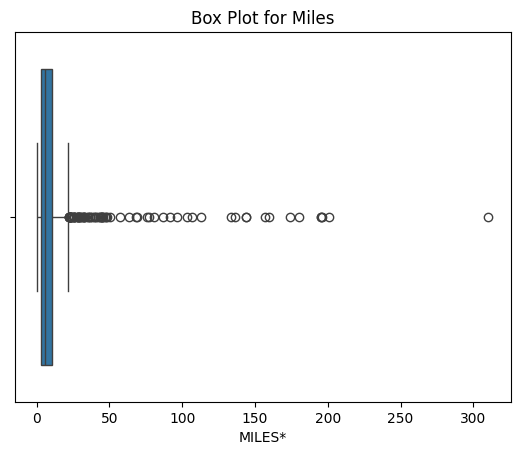

In [ ]:
sns.boxplot(x=data['MILES*'])
plt.title('Box Plot for Miles')
plt.show()

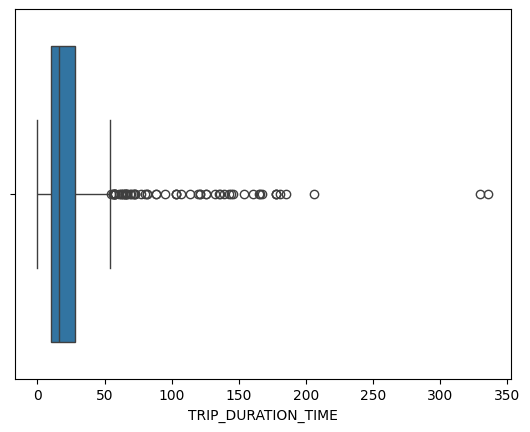

In [ ]:
sns.boxplot(x=data['TRIP_DURATION_TIME'])
plt.show()